# Basic States — CUDA-Q Implementation

**Primitive:** Basic States (computational basis state preparation)

**SETUP (must match the Qiskit notebook exactly for results to line up)**
- N QUBITS: 2
- TARGET STATE: `|10>` (qubit 1 = 1, qubit 0 = 0)
- ANCILLA QUBITS: none
- QUBIT ORDERING (contract): qubit 0 = rightmost bit in printed bitstring
- SHOTS: 10000
- SEED: 42
- GLOBAL PHASE: normalized so the first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** identical to the Qiskit version — a basis state is prepared from |00...0> by
applying a Pauli-X gate to every qubit that should be flipped to |1>. For target |10>, qubit
index 1 is flipped, qubit index 0 stays |0>.

**Important ordering warning:** CUDA-Q's native state-vector indexing treats qubit 0 as the
**most-significant** bit of the amplitude index (opposite of Qiskit, which treats qubit 0 as
least-significant/rightmost). This notebook explicitly reverses bit order after extracting the
state so the final printed dictionary matches the SETUP convention (qubit 0 = rightmost) and is
directly diffable against `QISKIT_RESULT`.
**IMPORTANT: Run every cell in order, top to bottom** (Kernel → Restart & Run All). All later cells depend on the constants defined in the first code cell.

In [1]:
# Run this cell first if you get ModuleNotFoundError.
# Correct package name is "cudaq" (NOT "cuda-quantum" -- that name has no prebuilt wheel and breaks pip).
# Requires pip >= 24.0, and Linux (x86_64/aarch64) or macOS (arm64/Apple Silicon). Windows needs WSL.
!pip install --upgrade pip -q
!pip install -q cudaq
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 17.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import cudaq

N_QUBITS = 2
TARGET_STATE = "10"   # bitstring in the SETUP convention: qubit0 = rightmost
SHOTS = 10000
SEED = 42

cudaq.set_random_seed(SEED)

# Precompute which qubit indices get an X gate (same logic as the Qiskit notebook)
bits_msb_first = TARGET_STATE
bits_for_qubit = bits_msb_first[::-1]   # index q -> bit assigned to qubit q
qubits_to_flip = [q for q in range(N_QUBITS) if bits_for_qubit[q] == "1"]
print("Qubits to flip with X:", qubits_to_flip)

Qubits to flip with X: [1]


## 1. Build the kernel explicitly, gate by gate

In [3]:
@cudaq.kernel
def basic_states_kernel():
    q = cudaq.qvector(2)
    # Basis-state preparation: Pauli-X flips |0> -> |1> on the target qubit(s).
    # Target |10> (SETUP convention, qubit0=rightmost) -> qubit index 1 is flipped.
    x(q[1])   # Oracle-free basis prep: X gate = theoretical Pauli-X operation on qubit 1
    # qubit 0 is left as |0> (no gate applied) to match target bit "0"

**Note:** the kernel above hardcodes the gate for `TARGET_STATE = "10"` on `N_QUBITS = 2`,
mirroring exactly the gates the Qiskit circuit applies (a single `X` on qubit 1, none on qubit 0).
If you change `TARGET_STATE` in the setup cell, update the `x(q[...])` calls here to match —
CUDA-Q kernels can't take the flip list as a runtime Python loop over `qubits_to_flip` the way
the Qiskit circuit builder does, since kernel bodies are compiled ahead-of-time.

## 2. Draw/visualize the circuit

In [4]:
# Native CUDA-Q text drawing
print(cudaq.draw(basic_states_kernel))

          
q0 : ─────
     ╭───╮
q1 : ┤ x ├
     ╰───╯



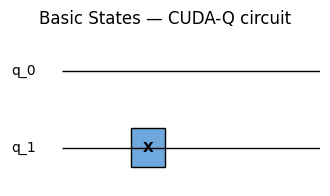

In [5]:
# Matplotlib circuit diagram, styled to resemble the Qiskit mpl output
fig, ax = plt.subplots(figsize=(4, 2))

wire_labels = [f"q_{i}" for i in range(N_QUBITS)]
for i, label in enumerate(wire_labels):
    y = N_QUBITS - 1 - i
    ax.hlines(y, 0, 3, color="black", linewidth=1)
    ax.text(-0.3, y, label, va="center", ha="right", fontsize=10)

# Draw the X gate box on qubit 1 at x-position 1
for q in qubits_to_flip:
    y = N_QUBITS - 1 - q
    ax.add_patch(plt.Rectangle((0.8, y - 0.25), 0.4, 0.5, facecolor="#6fa8dc", edgecolor="black"))
    ax.text(1.0, y, "X", va="center", ha="center", fontsize=10, fontweight="bold")

ax.set_xlim(-0.6, 3)
ax.set_ylim(-0.5, N_QUBITS - 0.5)
ax.axis("off")
ax.set_title("Basic States — CUDA-Q circuit")

fig.savefig("basic_states_cudaq_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator (Pauli-X)

In [6]:
X_matrix = np.array([[0, 1],
                      [1, 0]], dtype=complex)
print("Single-qubit Pauli-X gate matrix:")
print(X_matrix)

Single-qubit Pauli-X gate matrix:
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]


In [7]:
# Full 4x4 operator for the prep circuit, constructed manually from gate definitions
# (same tensor-product convention as Qiskit: qubit 0 rightmost in the basis ordering
# {|00>, |01>, |10>, |11>}).
I_matrix = np.eye(2, dtype=complex)

op_qubit0 = X_matrix if 0 in qubits_to_flip else I_matrix
op_qubit1 = X_matrix if 1 in qubits_to_flip else I_matrix

# Qiskit convention: kron(op_on_highest_index_qubit, ..., op_on_qubit0)
full_op = np.kron(op_qubit1, op_qubit0)

print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator (basis {{|00>, |01>, |10>, |11>}}):")
print(full_op.real if np.allclose(full_op.imag, 0) else full_op)

Full 4x4 operator (basis {|00>, |01>, |10>, |11>}):
[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


## 4. Exact statevector, reordered + global-phase normalized

In [8]:
state = cudaq.get_state(basic_states_kernel)
raw_amps = np.array(state)

print("Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):")
print(raw_amps)

Raw CUDA-Q amplitudes (native ordering, qubit0 = MSB):
[0.+0.j 0.+0.j 1.+0.j 0.+0.j]


In [9]:
# --- Explicit reindexing: CUDA-Q native (qubit0=MSB) -> SETUP convention (qubit0=rightmost/LSB) ---
def reorder_cudaq_to_qiskit_convention(amps, n_qubits):
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for cudaq_index in range(dim):
        # cudaq_index bit string, qubit0 = MSB (CUDA-Q native)
        cudaq_bits = format(cudaq_index, f"0{n_qubits}b")
        # reverse the bit string -> qubit0 = rightmost (SETUP / Qiskit convention)
        target_bits = cudaq_bits[::-1]
        target_index = int(target_bits, 2)
        reordered[target_index] = amps[cudaq_index]
    return reordered

amps_reordered = reorder_cudaq_to_qiskit_convention(raw_amps, N_QUBITS)
print("Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):")
print(amps_reordered)

Reordered amplitudes (qubit0 = rightmost, matches SETUP convention):
[0.+0.j 1.+0.j 0.+0.j 0.+0.j]


In [10]:
# Global phase normalization — identical method to the Qiskit notebook:
# find first nonzero amplitude in ascending bitstring order, rotate phase to real positive.
def normalize_global_phase(statevector_data, n_qubits):
    n = n_qubits
    dim = 2 ** n
    bitstrings = [format(i, f"0{n}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps_reordered, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    p = abs(amps_norm[i]) ** 2
    exact_probs[bs] = round(p, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.0), '01': np.float64(1.0), '10': np.float64(0.0), '11': np.float64(0.0)}


## 5. Measurement: sample, plot histogram

In [11]:
result = cudaq.sample(basic_states_kernel, shots_count=SHOTS)
raw_counts = {bs: result.count(bs) for bs in result}
print("Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):")
print(raw_counts)

Raw CUDA-Q counts (native bitstring ordering, qubit0 = MSB):
{'01': 10000}


In [12]:
# Reverse each sampled bitstring the same way as the statevector, to match SETUP convention
sampled_probs = {}
for bs, c in raw_counts.items():
    reordered_bs = bs[::-1]
    sampled_probs[reordered_bs] = sampled_probs.get(reordered_bs, 0) + c

sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in sampled_probs.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}), qubit0 = rightmost:")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42), qubit0 = rightmost:
{'10': 1.0}


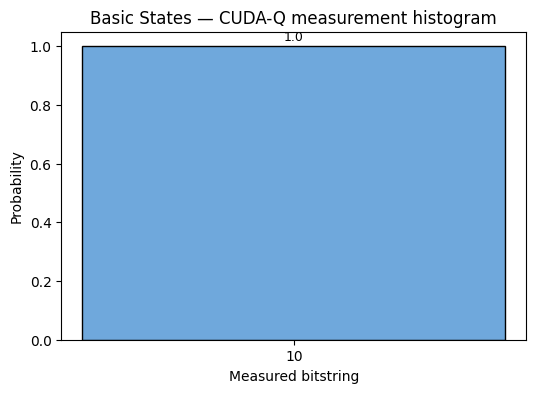

In [13]:
# Matplotlib bar chart styled like Qiskit's plot_histogram()
fig2, ax2 = plt.subplots(figsize=(6, 4))
labels = list(sampled_probs.keys())
values = list(sampled_probs.values())

ax2.bar(labels, values, color="#6fa8dc", edgecolor="black")
ax2.set_xlabel("Measured bitstring")
ax2.set_ylabel("Probability")
ax2.set_title("Basic States — CUDA-Q measurement histogram")
ax2.set_ylim(0, 1.05)
for i, v in enumerate(values):
    ax2.text(i, v + 0.02, str(v), ha="center", fontsize=9)

fig2.savefig("basic_states_cudaq_histogram.png", bbox_inches="tight")
fig2

## 6. Gate / operation count

In [14]:
gate_count = len(qubits_to_flip)  # number of X gates actually applied
print(f"Gate/operation count: {gate_count}")

Gate/operation count: 1


## 7. Convention notes

In [15]:
print("Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report")
print("bitstrings with qubit 0 as the MOST-significant (leftmost) bit — the opposite of Qiskit's")
print("convention. This notebook explicitly reversed every bitstring (both for the statevector")
print("amplitudes and the sampled counts) via string reversal / index remapping, so the final")
print("printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.")
print()
print("Global phase: computed and removed using the identical method as the Qiskit notebook —")
print("first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.")

Qubit ordering: CUDA-Q's cudaq.get_state() and cudaq.sample() natively index/report
bitstrings with qubit 0 as the MOST-significant (leftmost) bit — the opposite of Qiskit's
convention. This notebook explicitly reversed every bitstring (both for the statevector
amplitudes and the sampled counts) via string reversal / index remapping, so the final
printed results use qubit 0 = rightmost, matching the SETUP convention and the Qiskit output.

Global phase: computed and removed using the identical method as the Qiskit notebook —
first nonzero amplitude in ascending-bitstring order is rotated to be real and positive.


## Final result (for diffing against QISKIT_RESULT)

In [16]:
CUDAQ_RESULT = exact_probs
print("CUDAQ_RESULT =", CUDAQ_RESULT)

CUDAQ_RESULT = {'00': np.float64(0.0), '01': np.float64(1.0), '10': np.float64(0.0), '11': np.float64(0.0)}


## Quick diff check
Run this after both notebooks have produced `QISKIT_RESULT` and `CUDAQ_RESULT` (e.g. paste
the Qiskit dict in manually, or run both in the same kernel session).

In [17]:
# QISKIT_RESULT = {'00': 0.0, '01': 0.0, '10': 1.0, '11': 0.0}  # paste from the Qiskit notebook
#
# all_keys = sorted(set(QISKIT_RESULT) | set(CUDAQ_RESULT))
# max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
# print("Max probability delta:", max_delta)
# print("Match within tolerance:", max_delta < 1e-3)